# Decomposition experiments: summary figures

Figures for the main points of [FINDINGS.md](FINDINGS.md). Every figure reads the small tables in
`results/`; figure 3 also recomputes one example without training (a few seconds on CPU).
Arms: **A/B** original decomposition, **C/D** period-aware input with the original seasonal decoder,
**Cf/Df** period-aware input with a continuous-frequency Fourier decoder. B, D and Df have no
noise latent Z_n. Colour shows the family; open markers mark the arms without Z_n.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R = Path('results')
INK, INK2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e6e5e0', '#fcfcfb'
FAMILY = {'original': '#2a78d6', 'period': '#eb6834', 'fourier': '#1baf7a'}
REFERENCE = '#8a8984'
ARMS = {'A': ('original', True), 'B': ('original', False), 'C': ('period', True),
        'D': ('period', False), 'Cf': ('fourier', True), 'Df': ('fourier', False)}
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.titlelocation': 'left', 'font.size': 9.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'legend.frameon': False, 'figure.dpi': 110, 'lines.linewidth': 2})

def arm_marker(ax, x, y, arm, size=42, **kw):
    family, with_zn = ARMS[arm]
    c = FAMILY[family]
    ax.scatter(x, y, s=size, marker='o', facecolor=c if with_zn else SURFACE, edgecolor=c,
               linewidth=1.6, zorder=3, **kw)

## 1. The original input decomposition does not separate the components

Median error of each component on synthetic series with one seasonality (RMSE / std of the series).
The period-aware decomposition estimates the period of every window and fits a Fourier series at
that, possibly non-integer, period.

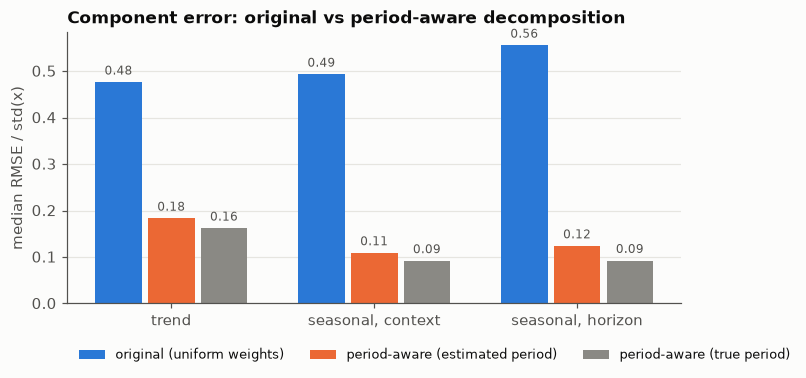

In [2]:
d = pd.read_csv(R / 'period_decomp_synthetic.csv').query("scenario == 'S1_single'").set_index('method')
methods = [('original_uniform_w', 'original (uniform weights)', FAMILY['original']),
           ('ours_est', 'period-aware (estimated period)', FAMILY['period']),
           ('ours_oracle_p', 'period-aware (true period)', REFERENCE)]
cols = [('trend_rmse', 'trend'), ('seas_rmse', 'seasonal, context'), ('seas_horizon_rmse', 'seasonal, horizon')]
fig, ax = plt.subplots(figsize=(7.2, 3.2))
w = 0.26
for i, (m, label, c) in enumerate(methods):
    xs = np.arange(len(cols)) + (i - 1) * w
    vals = [d.loc[m, col] for col, _ in cols]
    ax.bar(xs, vals, width=w - 0.03, color=c, label=label)
    for x, v in zip(xs, vals):
        ax.text(x, v + 0.01, f'{v:.2f}', ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_xticks(range(len(cols)), [name for _, name in cols])
ax.set_ylabel('median RMSE / std(x)')
ax.set_title('Component error: original vs period-aware decomposition')
ax.legend(loc='upper left', ncols=3, fontsize=8.5, bbox_to_anchor=(0, -0.12))
ax.grid(axis='x', visible=False)
plt.show()

## 2. The original seasonal decoder is exact only for a few periods

Identity check: the true top-32 rFFT coefficients of the context are passed through the original
reconstruction. *As implemented* rounds each bin index k·(T+L)/T and does not rescale the amplitude;
*rescaled* fixes the amplitude only; *exact frequency* evaluates the same bins at k/T.
Error on the 96-step horizon; a zero forecast scores 1.0.

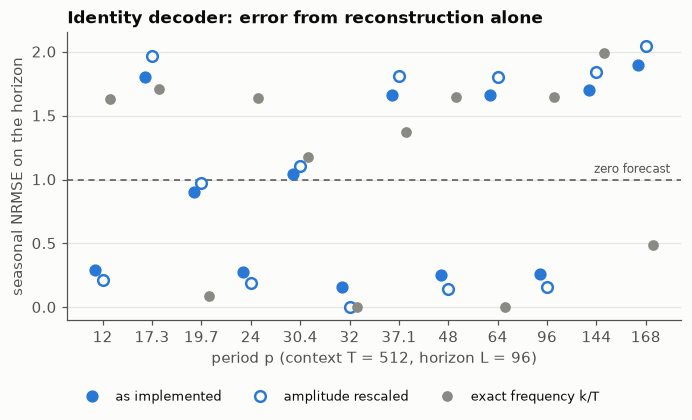

In [3]:
c = pd.read_csv(R / 'seasonal_decoder_identity_check.csv').query('K == 32').sort_values('period')
fig, ax = plt.subplots(figsize=(7.2, 3.4))
x = np.arange(len(c))
ax.axhline(1.0, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(len(c) - 0.5, 1.03, 'zero forecast', ha='right', va='bottom', fontsize=8, color=INK2)
ax.plot(x - 0.15, c.repo_horizon, 'o', color=FAMILY['original'], ms=7, label='as implemented')
ax.plot(x, c.rescaled_horizon, 'o', color=FAMILY['original'], ms=7, mfc=SURFACE, mew=1.6, label='amplitude rescaled')
ax.plot(x + 0.15, c.exact_k_horizon, 'o', color=REFERENCE, ms=6, label='exact frequency k/T')
ax.set_xticks(x, [f'{p:g}' for p in c.period])
ax.set_xlabel('period p (context T = 512, horizon L = 96)')
ax.set_ylabel('seasonal NRMSE on the horizon')
ax.set_title('Identity decoder: error from reconstruction alone')
ax.legend(loc='upper left', fontsize=8.5, ncols=3, bbox_to_anchor=(0, -0.2))
ax.grid(axis='x', visible=False)
plt.show()

Only p = 32 is transferred exactly (every bin maps to an integer index); its remaining error, 0.16,
is the missing amplitude factor T/(T+L). For 12, 24, 48 and 96 the rounding happens to land close
to the right frequency. Evaluating at the exact frequency k/T fixes rounding but repeats the
context with period T, which is wrong whenever p does not divide T.

## 3. One example: period 37.1

A noisy series with three harmonics of period 37.1. *Period-aware input + original decoder* (arm C
path): top-16 bins of the period-aware seasonal estimate, reconstructed by the original decoder.
*Fourier decoder* (arm Cf path, correction set to zero): the Fourier series at the estimated period.

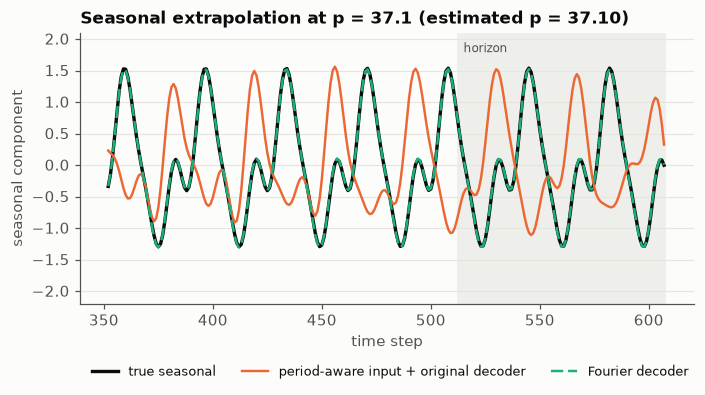

horizon NRMSE: original decoder 1.62, Fourier 0.02


In [4]:
sys.path.insert(0, str(Path.cwd()))
from paths import REPO_ROOT, PERIOD_DECOMP_DIR
sys.path.insert(0, str(REPO_ROOT)); sys.path.insert(0, str(PERIOD_DECOMP_DIR))
import torch
import period_decomp as pdm
from decovaefm.models.decovae_fm import DecoVAEFM

T, L, p = 512, 96, 37.1
t = np.arange(T + L)
rng = np.random.default_rng(3)
truth = sum(a * np.sin(2 * np.pi * h * t / p + ph) for h, a, ph in zip((1, 2, 3), (1, .5, .3), rng.uniform(-np.pi, np.pi, 3)))
x = truth + 0.1 * rng.normal(size=T + L)
dec = pdm.decompose(x[:T])
fourier = dec.seasonal_at(t)
fft = torch.fft.rfft(torch.tensor(dec.seasonal))
idx = torch.topk(fft.abs(), 16).indices
original = DecoVAEFM._reconstruct_time_from_freq_tokens(None, fft[idx][None, :, None], idx[None], T, T + L)[0].numpy()

show = slice(T - 160, T + L)
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.axvspan(T, T + L, color=GRID, alpha=0.6, lw=0)
ax.text(T + 3, 1.95, 'horizon', fontsize=8, color=INK2, va='top')
ax.plot(t[show], truth[show], color=INK, lw=2.2, label='true seasonal')
ax.plot(t[show], original[show], color=FAMILY['period'], lw=1.6, label='period-aware input + original decoder')
ax.plot(t[show], fourier[show], color=FAMILY['fourier'], lw=1.6, ls=(0, (5, 2)), label='Fourier decoder')
ax.set_ylim(-2.2, 2.1)
ax.set_xlabel('time step'); ax.set_ylabel('seasonal component')
ax.set_title(f'Seasonal extrapolation at p = {p} (estimated p = {dec.seasons[0].period:.2f})')
ax.legend(loc='lower left', fontsize=8.5, ncols=3, bbox_to_anchor=(0, -0.32))
ax.grid(axis='x', visible=False)
plt.show()
nrmse = lambda e, s: np.sqrt(np.mean((e[s] - truth[s]) ** 2)) / truth[s].std()
print(f'horizon NRMSE: original decoder {nrmse(original, slice(T, None)):.2f}, Fourier {nrmse(fourier, slice(T, None)):.2f}')

## 4. Forecast quality by mechanism

CRPS on the diagnostic suite (64 series per case, mean over three seeds; lower is better).
Cases are ordered by the difference between Cf and A.

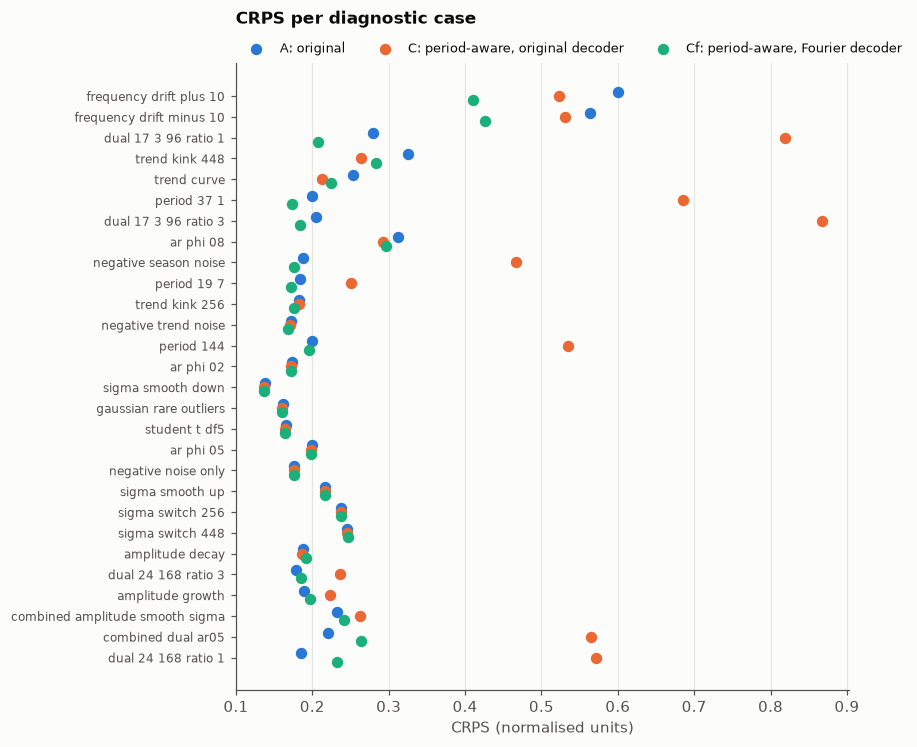

In [5]:
dc = pd.read_csv(R / 'diagnostic_crps_by_case.csv').set_index('case')
drop = {'sigma_unseen_future_jump'}  # unpredictable by design
dc = dc.drop(index=[c for c in dc.index if c in drop])
dc = dc.assign(gap=dc.Cf - dc.A).sort_values('gap')
fig, ax = plt.subplots(figsize=(7.2, 7.4))
y = np.arange(len(dc))
for arm, off in (('A', -0.2), ('C', 0.0), ('Cf', 0.2)):
    arm_marker(ax, dc[arm], y + off, arm, size=34, label={'A': 'A: original', 'C': 'C: period-aware, original decoder',
                                                    'Cf': 'Cf: period-aware, Fourier decoder'}[arm])
ax.set_yticks(y, [c.replace('_', ' ') for c in dc.index], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('CRPS (normalised units)')
ax.set_title('CRPS per diagnostic case', pad=26)
ax.legend(loc='lower left', fontsize=8.5, ncols=3, bbox_to_anchor=(0, 1.0), borderaxespad=0.2)
ax.grid(axis='y', visible=False)
plt.show()

C fails on off-grid periods and dual seasonality (top-right markers); Cf removes those failures.
Cf is still worse than A where the amplitude drifts or the second period is long (24 + 168):
there the deterministic Fourier extrapolation itself is poor, so the loss comes from the period
estimate and the stationary Fourier form rather than from the decoder.

## 5. The noise latent has no consistent effect on Gaussian synthetic data

G = CRPS without Z_n − CRPS with Z_n, per training seed with a 95 % paired bootstrap interval.
Positive G means Z_n helps. Typical CRPS is about 0.2.

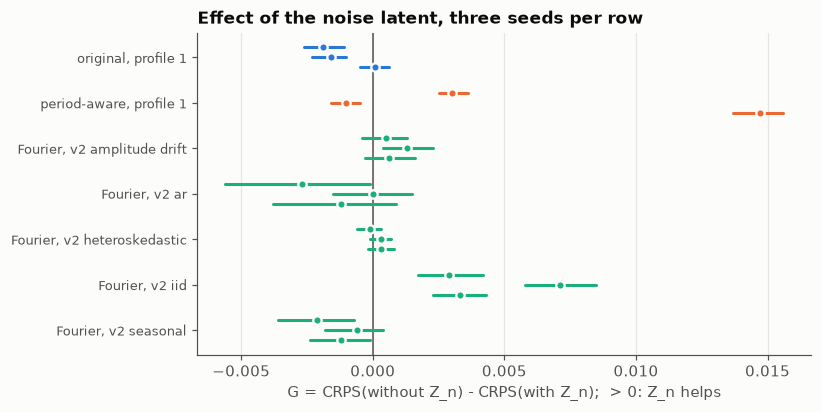

In [6]:
v1 = pd.read_csv(R / 'v1_noise_branch_effects.csv').query("effect in ['G_original', 'G_period']")
v2 = pd.read_csv(R / 'v2_test_paired_by_seed.csv').query("pair == 'Cf-Df'")
rows = [(f'{"original" if r.effect == "G_original" else "period-aware"}, profile 1', r.seed, r['mean'], r.ci95_low, r.ci95_high,
         'original' if r.effect == 'G_original' else 'period') for _, r in v1.iterrows()]
# Cf - Df < 0 means Z_n helps, so G = -(Cf - Df)
rows += [(f'Fourier, v2 {r.block.replace("_", " ")}', r.seed, -r['mean'], -r.ci_high, -r.ci_low, 'fourier') for _, r in v2.iterrows()]
e = pd.DataFrame(rows, columns=['group', 'seed', 'g', 'lo', 'hi', 'family'])
groups = list(dict.fromkeys(e.group))
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.axvline(0, color=INK2, lw=1)
for gi, g in enumerate(groups):
    sub = e[e.group == g]
    for k, (_, r) in enumerate(sub.iterrows()):
        yy = gi + (k - 1) * 0.22
        ax.plot([r.lo, r.hi], [yy, yy], color=FAMILY[r.family], lw=2, solid_capstyle='round')
        ax.scatter(r.g, yy, s=30, color=FAMILY[r.family], edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(range(len(groups)), groups, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel('G = CRPS(without Z_n) - CRPS(with Z_n);  > 0: Z_n helps')
ax.set_title('Effect of the noise latent, three seeds per row')
ax.grid(axis='y', visible=False)
plt.show()

The sign changes with the seed in most rows; effects are a few thousandths of CRPS. The only
row with the same sign in every seed is the Fourier arm on the iid block, and it is small.

## 6. How the predicted variance responds to input changes

Ratio of predicted forecast variance (modified / base input), median over 64 series; marker = median
over seeds, bar = range over seeds. Dashed line: ideal ratio.

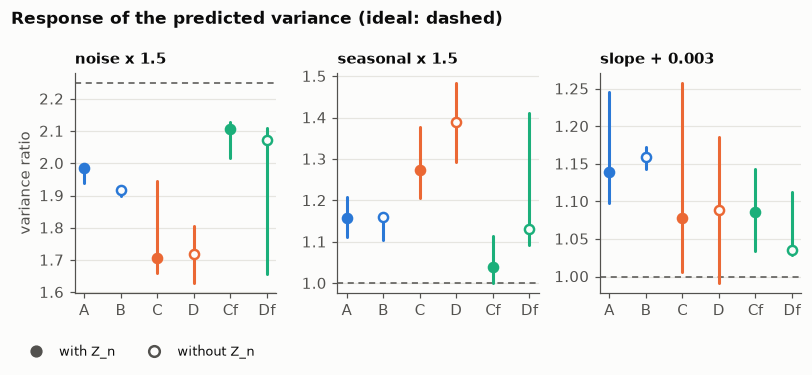

In [7]:
iv = pd.read_csv(R / 'interventions_by_run.csv')
kinds = [('noise', 'noise x 1.5', 2.25), ('seasonal', 'seasonal x 1.5', 1.0), ('slope', 'slope + 0.003', 1.0)]
order = ['A', 'B', 'C', 'D', 'Cf', 'Df']
fig, axes = plt.subplots(1, 3, figsize=(7.4, 3.0), sharey=False)
for ax, (kind, title, ideal) in zip(axes, kinds):
    sub = iv[iv.kind == kind]
    ax.axhline(ideal, color=INK2, lw=1, ls=(0, (4, 3)))
    for i, arm in enumerate(order):
        s = sub[sub.arm == arm]['median']
        ax.plot([i, i], [s.min(), s.max()], color=FAMILY[ARMS[arm][0]], lw=2, solid_capstyle='round')
        arm_marker(ax, i, s.median(), arm, size=36)
    ax.set_xticks(range(len(order)), order)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('variance ratio')
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker='o', ls='', color=INK2, ms=7, label='with Z_n'),
           Line2D([], [], marker='o', ls='', color=INK2, mfc=SURFACE, mew=1.6, ms=7, label='without Z_n')]
fig.legend(handles=handles, loc='lower left', ncols=2, fontsize=8.5, bbox_to_anchor=(0.01, -0.11))
fig.suptitle('Response of the predicted variance (ideal: dashed)', x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout()
plt.show()

Every arm reacts to more noise, with or without Z_n. Seasonal amplitude leaks into the predicted
variance in all arms, least in Cf. (D has two seeds.)

## 7. Room for a better noise model

CRPS gain of a Gaussian forecast that knows the true conditional variance, over a constant σ from
the context (true mean in both; horizon steps 1-32). *Realistic*: typical GARCH / stochastic
volatility / regime parameters; *strong*: high persistence and volatility of volatility.

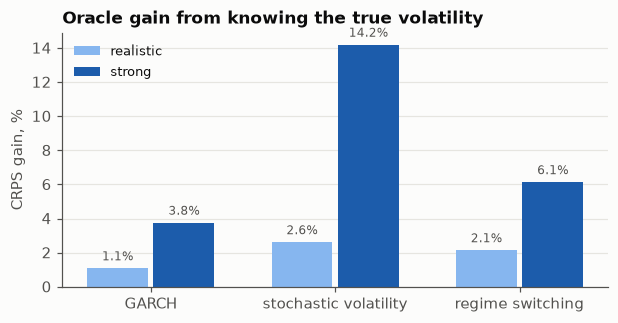

In [8]:
blocks = [('garch', 'GARCH'), ('sv', 'stochastic volatility'), ('regime', 'regime switching')]
prof = {'realistic': '#86b6ef', 'strong': '#1c5cab'}
fig, ax = plt.subplots(figsize=(6.4, 3.0))
w = 0.36
for j, (name, file) in enumerate([('realistic', 'h1_headroom_base.csv'), ('strong', 'h1_headroom_strong.csv')]):
    h = pd.read_csv(R / file).query("bucket == 'h1'").set_index('block')
    vals = [100 * h.loc[b, 'headroom_vs_context_const'] for b, _ in blocks]
    xs = np.arange(len(blocks)) + (j - 0.5) * w
    ax.bar(xs, vals, width=w - 0.03, color=prof[name], label=name)
    for xx, v in zip(xs, vals):
        ax.text(xx, v + 0.3, f'{v:.1f}%', ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_xticks(range(len(blocks)), [n for _, n in blocks])
ax.set_ylabel('CRPS gain, %')
ax.set_title('Oracle gain from knowing the true volatility')
ax.legend(loc='upper left', fontsize=8.5)
ax.grid(axis='x', visible=False)
plt.show()

## 8. Zero-shot transfer to real windows

Coverage of the 90 % interval for models trained only on synthetic data (5-8 windows per source;
marker = mean over seeds, bar = range over seeds). These are tendencies, not established differences.

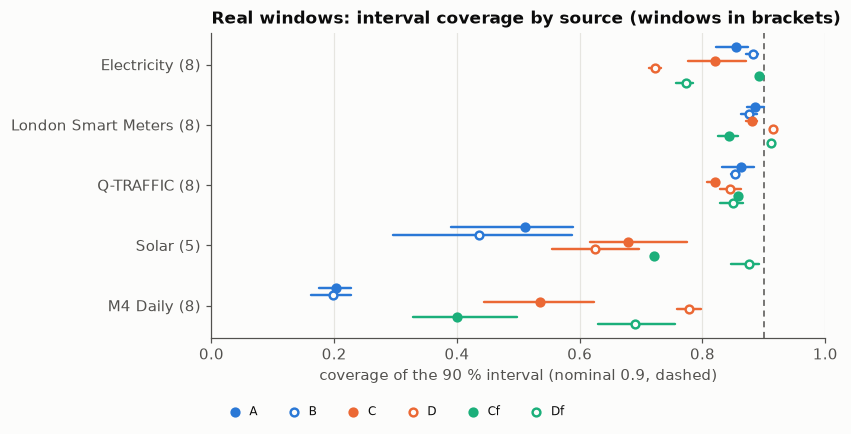

In [9]:
rt = pd.read_csv(R / 'real_transfer_by_seed.csv')
sources = ['Electricity', 'London_Smart_Meters', 'Q-TRAFFIC', 'Solar', 'M4_Daily']
order = ['A', 'B', 'C', 'D', 'Cf', 'Df']
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.axvline(0.9, color=INK2, lw=1, ls=(0, (4, 3)))
for si, src in enumerate(sources):
    for k, arm in enumerate(order):
        s = rt[(rt.dataset == src) & (rt.arm == arm)].coverage90
        yy = si + (k - 2.5) * 0.12
        ax.plot([s.min(), s.max()], [yy, yy], color=FAMILY[ARMS[arm][0]], lw=1.6, solid_capstyle='round')
        arm_marker(ax, s.mean(), yy, arm, size=26, label=arm if si == 0 else None)
ax.set_yticks(range(len(sources)), [f'{s.replace("_", " ")} ({rt[rt.dataset == s].windows.max()})' for s in sources])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('coverage of the 90 % interval (nominal 0.9, dashed)')
ax.set_title('Real windows: interval coverage by source (windows in brackets)')
ax.legend(loc='lower left', ncols=6, fontsize=8, bbox_to_anchor=(0, -0.3), handletextpad=0.2)
ax.grid(axis='y', visible=False)
plt.show()